# [Lab Session 4](deconvolution.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

In [2]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

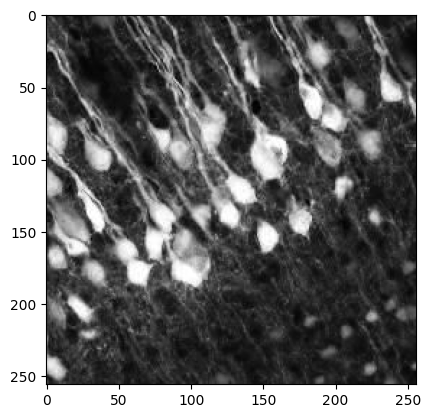

In [3]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

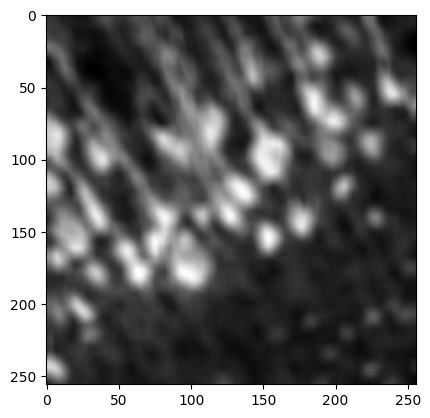

In [4]:
img_psf = conv(img, psf, mode='same', boundary='symm')

plt.figure()
plt.imshow(img_psf, 'gray')
plt.show()

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

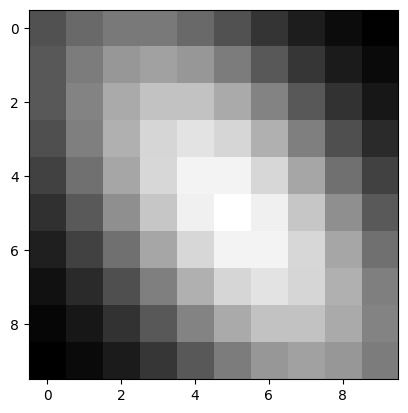

In [6]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y 
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])  
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'grey')

Apply the second psf to the image:

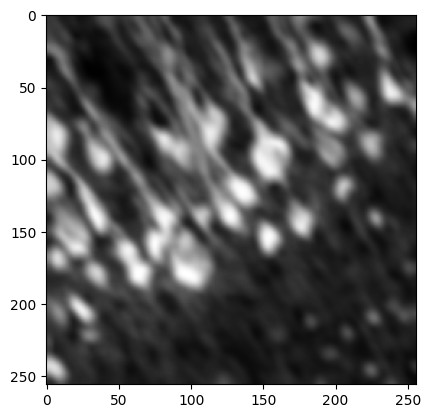

In [7]:
psf_gauss = create_psf(psf_size)

img_gauss = conv(img, psf_gauss, mode='same', boundary='symm')

plt.figure()
plt.imshow(img_gauss, 'gray')
plt.show()

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [16]:
def richardson_lucy(g, psf, t_iterations):
    h = np.full(g.shape, 0.5)
    psf_flipped = np.flip(psf)
    
    for _ in range(t_iterations):
        bruch = g / conv(h, psf, mode='same', boundary='symm')
        h = h * conv(bruch, psf_flipped, mode='same', boundary='symm')
    h = h.clip(0,1)    
    return h

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [17]:
deconv_img = richardson_lucy(img_psf, psf, t_iterations = 50)

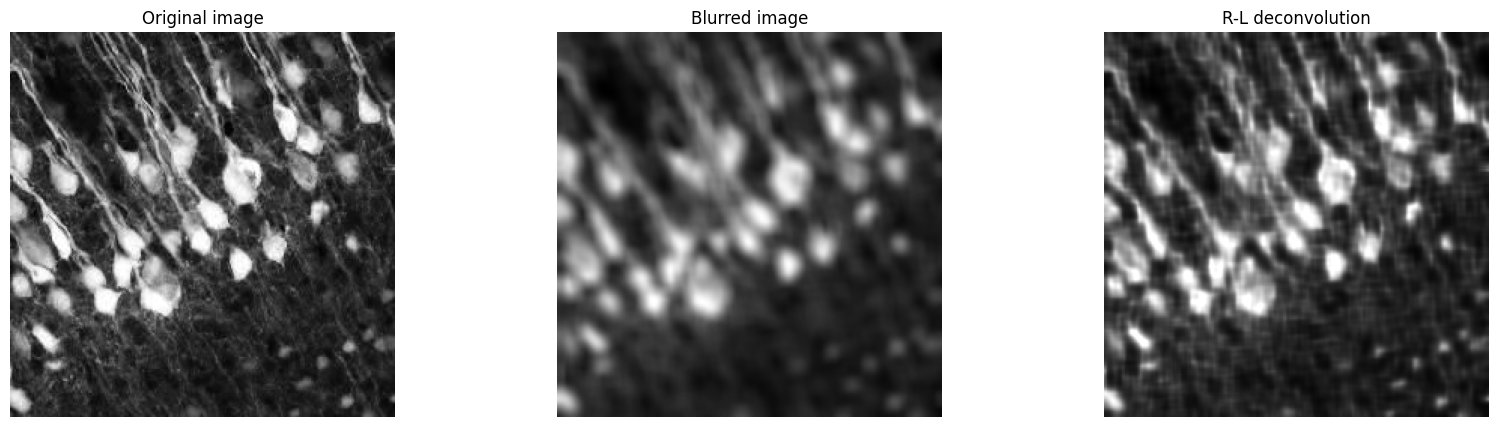

In [18]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_psf, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [19]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

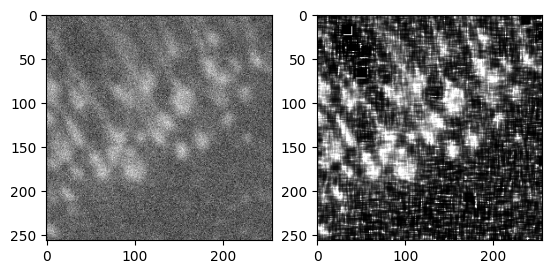

In [28]:
img_noise = (img_psf + noise)
img_noise_clip = img_noise.clip(0,1)

img_noise_RL = richardson_lucy(img_noise, psf, t_iterations = 15)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(img_noise, 'grey')
plt.subplot(1, 2, 2)
plt.imshow(img_noise_RL, 'grey')
plt.show()


**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

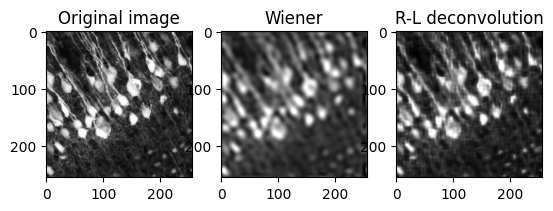

In [ ]:
img_wiener = wiener(img_psf, psf, balance=2, clip=True)

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.imshow(img_wiener , 'gray')
plt.title('Wiener')
plt.subplot(1, 3, 3)
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

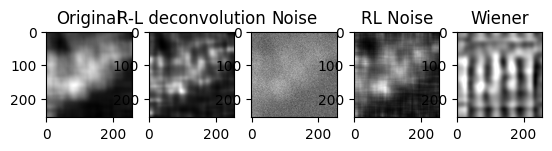

In [38]:
psf_size_50 = 50
psf_50 = np.ones((psf_size_50, psf_size_50)) / psf_size_50 ** 2

img_psf_50 = conv(img, psf_50, mode='same', boundary='symm')

deconv_img_50 = richardson_lucy(img_psf_50, psf_50, t_iterations = 50)

noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

img_noise_50 = (img_psf_50 + noise)
img_noise_clip_50= img_noise_50.clip(0,1)

img_noise_RL_50 = richardson_lucy(img_noise_50, psf_50, t_iterations = 15)

img_wiener_50 = wiener(img_psf_50, psf_50, balance=2, clip=True)

plt.figure()
plt.subplot(1, 5, 1)
plt.imshow(img_psf_50, 'gray')
plt.title('Original')
plt.subplot(1, 5, 2)
plt.imshow(deconv_img_50, 'gray')
plt.title('R-L deconvolution')
plt.subplot(1, 5, 3)
plt.imshow(img_noise_50, 'grey')
plt.title('Noise')
plt.subplot(1, 5, 4)
plt.imshow(img_noise_RL_50, 'grey')
plt.title('RL Noise')
plt.subplot(1, 5, 5)
plt.imshow(img_wiener_50 , 'gray')
plt.title('Wiener')
plt.show()

**[Task 8.]()** Use a wrong PSF to restore the image

<function matplotlib.pyplot.show(close=None, block=None)>

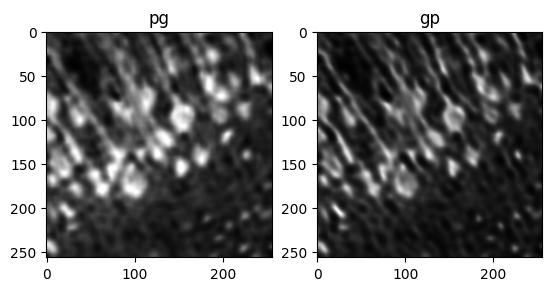

In [41]:
img_p_g = richardson_lucy(img_psf, psf_gauss, t_iterations = 15)

img_g_p = richardson_lucy(img_gauss, psf, t_iterations = 15)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(img_p_g, 'gray')
plt.title('pg')
plt.subplot(1, 2, 2)
plt.imshow(img_g_p, 'gray')
plt.title('gp')
plt.show